In [18]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_csv("salary_loan_dataset.csv")
np.random.seed(42)
df["Loan_Amount"] = (
    0.45 * df["Annual_Salary"]
    + np.random.normal(0, 300000, len(df))
).clip(lower=0)
df.to_csv("salary_loan_dataset.csv", index=False)

In [ ]:
df.head(35) # Show first 35 rows of the data

,Annual_Salary,Loan_Amount
0,1.248712e+06,3.845869e+06
1,2.862000e+06,7.616407e+06
2,2.249583e+06,9.353302e+06
3,1.876244e+06,5.105373e+06
4,6.368522e+05,1.523048e+06
5,6.367847e+05,2.204662e+06
6,3.626341e+05,6.712507e+05
7,2.625293e+06,9.647587e+06
8,1.883122e+06,3.918006e+06
9,2.182603e+06,7.088864e+06


In [ ]:
df.columns # Shows all the feature names for the data

Index(['Annual_Salary', 'Loan_Amount'], dtype='object')

In [19]:
#Make a new Dataset considering only ‘Avg. Area House Age’ and ‘Price’ attributes

df_binary = df[['Annual_Salary', 'Loan_Amount']].copy() # to create copy of original data
df_binary_columns = ['Annual_Salary', 'Loan_Amount']
df_binary.head()

,Annual_Salary,Loan_Amount
0,1.248712e+06,7.109348e+05
1,2.862000e+06,1.246421e+06
2,2.249583e+06,1.206619e+06
3,1.876244e+06,1.301219e+06
4,6.368522e+05,2.163375e+05


In [20]:
#Split the new dataset into the Training set and Test set such that Test set contains 1/3 of total records using model_selection.train_test_split from sklearn.

X = np.array(df_binary['Annual_Salary']).reshape(-1,1) #changes the dimension of the numpy array
Y = np.array(df_binary['Loan_Amount']).reshape(-1,1)

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.33) #splits the data into two parts (training,testing)

In [21]:
#Train the Simple Linear Regression model based on the Training set after importing LinearRegression from sklearn.linear_model.

lr=LinearRegression() # Creating an Object of LinearRegeression Class to create a model
lr.fit(x_train,y_train) # to train the model 

LinearRegression()

In [22]:
#Display the model’s coefficients after train the model and hence write the final regression model.

print(lr.score(x_test,y_test)) # returns the r2 value
lr.coef_
lr.intercept_

m=lr.intercept_ # intercept or the bias of the LR equation
b=lr.coef_      # Slopw or the Co-efficient of the LR equation
print('y=',m,'*X+',b) 

0.617604079439593
y= [35316.86695429] *X+ [[0.44538063]]


In [23]:
#Predict the house price of the Test set data and display them

y_pred = lr.predict(x_test) # Predict the output value for the given input using the trained model
print(y_pred)

[[ 957698.29134207]
 [ 697794.35557501]
 [ 350083.15278681]
 [ 816967.8590236 ]
 [ 199394.44835444]
 [1366887.42659619]
 [ 309785.18940502]
 [ 761328.4635229 ]
 [ 763749.27809279]
 [1235707.05337958]
 [ 243755.33695904]
 [ 399510.6040366 ]
 [ 895397.34659139]
 [ 170393.44129555]
 [ 946066.49959426]
 [ 876563.33390378]
 [1307715.65247631]
 [1326090.46783273]
 [ 169972.8315728 ]
 [ 178216.24063323]
 [1097759.6343124 ]
 [ 381813.8917657 ]
 [ 785714.62322206]
 [ 322561.92668194]
 [ 945939.16978846]
 [1301144.09346032]
 [ 991283.96137167]
 [1174420.5544916 ]
 [ 345261.65574716]
 [1126624.91872683]
 [ 809692.4586427 ]
 [1170554.06896083]
 [ 332695.30669552]
 [ 428031.42670366]
 [1138134.00407851]
 [1362685.38676748]
 [1073398.51002674]
 [ 415717.21911949]
 [ 175242.27513618]
 [1052142.93833014]
 [1302535.94619937]
 [1362085.18155013]
 [ 276582.6960224 ]
 [ 619836.36783631]
 [1213013.85135183]
 [1264724.81723689]
 [ 550661.70658146]
 [ 181436.31638563]
 [ 591881.25513548]
 [ 567580.91829419]


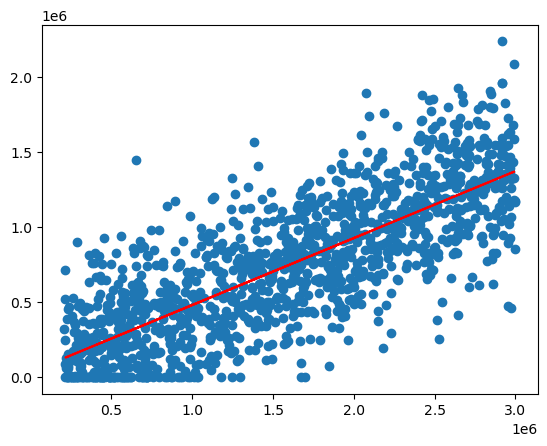

In [24]:
#Visualize the Training set results using scatter plot along with regression line.

plt.scatter(x_train,y_train) # Creates Scatter Plot
plt.plot(x_test,y_pred,color='red') # Plots the regression line

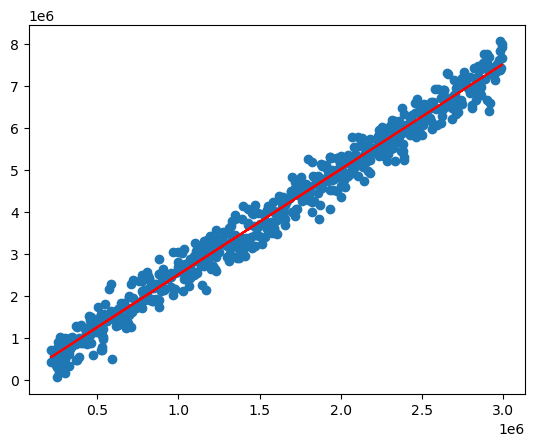

In [10]:
#Visualize the Test set results using scatter plot along with regression line

plt.scatter(x_test,y_test)
plt.plot(x_test,y_pred,color='red')